In [35]:
import pandas as pd
import numpy as np
from pathlib import Path

# Locate project folders
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

# Dataset paths
DATA_FILE = RAW_DIR / "i_i4249_data.xlsx"
META_FILE = RAW_DIR / "i_i4249_metadata.xlsx"

# Verify files
print("Data file exists:", DATA_FILE.exists())
print("Metadata file exists:", META_FILE.exists())

Data file exists: True
Metadata file exists: True


In [36]:
# Inspect workbook sheets
data_excel = pd.ExcelFile(DATA_FILE)
metadata_excel = pd.ExcelFile(META_FILE)

print("Data sheets:", data_excel.sheet_names)
print("Metadata sheets:", metadata_excel.sheet_names)

Data sheets: ['Data']
Metadata sheets: ['Metadata']


c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [37]:
# Display the first 10 rows without assuming the header position
raw_preview = pd.read_excel(
    DATA_FILE,
    sheet_name=data_excel.sheet_names[0],
    header=None,
    nrows=10
)

display(raw_preview)

,0,1,2,3,4,5,6,7,8,9,...,72,73,74,75,76,77,78,79,80,81
0,Taux de chômage selon les tranches d'âge et le...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Tranches d'âge,Milieu,T4-2025,T3-2025,T2-2025,T1-2025,T4-2024,T3-2024,T2-2024,T1-2024,...,T2-2008,T1-2008,T4-2007,T3-2007,T2-2007,T1-2007,T4-2006,T3-2006,T2-2006,T1-2006
2,Ensemble,National,12.9,13.1,12.8,13.3,12.9,13.6,13.1,13.7,...,9.1,9.6,9.7,9.9,9.3,10.1,10.9,10.1,7.8,9.6
3,Ensemble,Rural,6.2,6.9,6.2,7.3,6.2,7.4,6.7,6.8,...,3.9,4,4.1,3.5,3.4,3.9,4.4,3.9,2.4,3.7
4,Ensemble,Urbain,16.5,16.3,16.4,16.6,16.5,17,16.7,17.6,...,14,14.6,14.8,15.9,15,15.8,17.2,16,13.2,15.3
5,15 - 24,National,37.2,38.4,35.8,37.7,35.7,39.5,36.1,35.9,...,17.3,17.9,18.6,16.7,15.5,17.6,19.4,17.5,13.1,16.2
6,15 - 24,Rural,20.4,24.3,21.3,25.5,20.6,24.7,20.2,20.2,...,8.5,9.1,7.8,5.9,6.2,7.6,7.9,6.7,4.3,6.4
7,15 - 24,Urbain,50.1,48.2,46.9,46.9,47.3,50.3,48.8,47.7,...,30,30.3,33.6,32.1,28.5,31.8,35.6,32.6,27,30.8
8,25 - 34,National,20,20.8,21.9,21.2,20.1,20.9,21.4,22,...,13.2,13.5,13.7,14.8,14.4,14.2,15.2,14.2,11.7,14.1
9,25 - 34,Rural,7.8,9.3,9,10.4,7.8,9,10,10,...,4.2,4.5,5.3,4.7,4.4,4.4,5.6,4.6,2.9,4.4


In [38]:
metadata_preview = pd.read_excel(
    META_FILE,
    sheet_name=metadata_excel.sheet_names[0],
    header=None
)

display(metadata_preview)

c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,0,1
0,L'indicateur,Taux de chômage selon les tranches d'âge et le...
1,Définition,Pour plus d'information consulter la BDS en li...
2,Périodicité,Trimestrielle
3,Unité,%
4,Source,"Enquête nationale sur l'emploi, Haut Commissar..."


In [39]:
# Load the second HCP dataset

df_age_raw = pd.read_excel(
    DATA_FILE,
    sheet_name="Data",
    header=1
)

print("Dataset shape:", df_age_raw.shape)

print("\nFirst 5 rows:")
display(df_age_raw.head())

print("\nColumn names:")
print(df_age_raw.columns.tolist())

Dataset shape: (15, 82)

First 5 rows:


c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,Tranches d'âge,Milieu,T4-2025,T3-2025,T2-2025,T1-2025,T4-2024,T3-2024,T2-2024,T1-2024,...,T2-2008,T1-2008,T4-2007,T3-2007,T2-2007,T1-2007,T4-2006,T3-2006,T2-2006,T1-2006
0,Ensemble,National,12.9,13.1,12.8,13.3,12.9,13.6,13.1,13.7,...,9.1,9.6,9.7,9.9,9.3,10.1,10.9,10.1,7.8,9.6
1,Ensemble,Rural,6.2,6.9,6.2,7.3,6.2,7.4,6.7,6.8,...,3.9,4.0,4.1,3.5,3.4,3.9,4.4,3.9,2.4,3.7
2,Ensemble,Urbain,16.5,16.3,16.4,16.6,16.5,17.0,16.7,17.6,...,14.0,14.6,14.8,15.9,15.0,15.8,17.2,16.0,13.2,15.3
3,15 - 24,National,37.2,38.4,35.8,37.7,35.7,39.5,36.1,35.9,...,17.3,17.9,18.6,16.7,15.5,17.6,19.4,17.5,13.1,16.2
4,15 - 24,Rural,20.4,24.3,21.3,25.5,20.6,24.7,20.2,20.2,...,8.5,9.1,7.8,5.9,6.2,7.6,7.9,6.7,4.3,6.4



Column names:
["Tranches d'âge", 'Milieu', 'T4-2025', 'T3-2025', 'T2-2025', 'T1-2025', 'T4-2024', 'T3-2024', 'T2-2024', 'T1-2024', 'T4-2023', 'T3-2023', 'T2-2023', 'T1-2023', 'T4-2022', 'T3-2022', 'T2-2022', 'T1-2022', 'T4-2021', 'T3-2021', 'T2-2021', 'T1-2021', 'T4-2020', 'T3-2020', 'T2-2020', 'T1-2020', 'T4-2019', 'T3-2019', 'T2-2019', 'T1-2019', 'T4-2018', 'T3-2018', 'T2-2018', 'T1-2018', 'T4-2017', 'T3-2017', 'T2-2017', 'T1-2017', 'T4-2016', 'T3-2016', 'T2-2016', 'T1-2016', 'T4-2015', 'T3-2015', 'T2-2015', 'T1-2015', 'T4-2014', 'T3-2014', 'T2-2014', 'T1-2014', 'T4-2013', 'T3-2013', 'T2-2013', 'T1-2013', 'T4-2012', 'T3-2012', 'T2-2012', 'T1-2012', 'T4-2011', 'T3-2011', 'T2-2011', 'T1-2011', 'T4-2010', 'T3-2010', 'T2-2010', 'T1-2010', 'T4-2009', 'T3-2009', 'T2-2009', 'T1-2009', 'T4-2008', 'T3-2008', 'T2-2008', 'T1-2008', 'T4-2007', 'T3-2007', 'T2-2007', 'T1-2007', 'T4-2006', 'T3-2006', 'T2-2006', 'T1-2006']


In [40]:
# Inspect identification columns

print("Age categories:")
print(df_age_raw["Tranches d'âge"].unique())

print("\nResidence categories:")
print(df_age_raw["Milieu"].unique())

print("\nData types:")
print(df_age_raw.dtypes.value_counts())

print("\nMissing values:")
print(df_age_raw.isna().sum().sum())

print("\nDuplicate rows:")
print(df_age_raw.duplicated().sum())

Age categories:
<ArrowStringArray>
['Ensemble', '15 - 24 ', '25 - 34 ', '35 - 44 ', '45 et plus ']
Length: 5, dtype: str

Residence categories:
<ArrowStringArray>
['National', 'Rural', 'Urbain']
Length: 3, dtype: str

Data types:
float64    80
str         2
Name: count, dtype: int64

Missing values:
0

Duplicate rows:
0


In [41]:
# Identify quarterly columns

quarter_cols = [
    col for col in df_age_raw.columns
    if col not in ["Tranches d'âge", "Milieu"]
]

print("Number of quarterly columns:", len(quarter_cols))

print("\nFirst 10 quarters:")
print(quarter_cols[:10])

print("\nLast 10 quarters:")
print(quarter_cols[-10:])

Number of quarterly columns: 80

First 10 quarters:
['T4-2025', 'T3-2025', 'T2-2025', 'T1-2025', 'T4-2024', 'T3-2024', 'T2-2024', 'T1-2024', 'T4-2023', 'T3-2023']

Last 10 quarters:
['T2-2008', 'T1-2008', 'T4-2007', 'T3-2007', 'T2-2007', 'T1-2007', 'T4-2006', 'T3-2006', 'T2-2006', 'T1-2006']


## 2. Nettoyage et préparation des données

### 2.1 Nettoyage des catégories et vérification des valeurs

In [42]:
# Create a copy of the original dataset
df_age_clean = df_age_raw.copy()

# Identify the columns
id_cols = ["Tranches d'âge", "Milieu"]

quarter_cols = [
    col for col in df_age_clean.columns
    if col not in id_cols
]

# Clean categorical values
df_age_clean["Tranches d'âge"] = (
    df_age_clean["Tranches d'âge"].str.strip()
)

df_age_clean["Milieu"] = (
    df_age_clean["Milieu"].str.strip()
)

# Convert quarterly values to numeric
df_age_clean[quarter_cols] = df_age_clean[quarter_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

# Validate the cleaned dataset
print("Dataset shape:", df_age_clean.shape)

print("\nAge categories:")
print(df_age_clean["Tranches d'âge"].unique())

print("\nResidence categories:")
print(df_age_clean["Milieu"].unique())

print("\nMissing values:", df_age_clean.isna().sum().sum())

print(
    "\nDuplicate age/residence combinations:",
    df_age_clean.duplicated(subset=id_cols).sum()
)

print(
    "\nNumber of quarterly columns:",
    len(quarter_cols)
)

print(
    "\nValues outside the expected 0-100% range:",
    ((df_age_clean[quarter_cols] < 0) |
     (df_age_clean[quarter_cols] > 100)).sum().sum()
)

display(df_age_clean.head())

Dataset shape:

 (15, 82)

Age categories:
<ArrowStringArray>
['Ensemble', '15 - 24', '25 - 34', '35 - 44', '45 et plus']
Length: 5, dtype: str

Residence categories:
<ArrowStringArray>
['National', 'Rural', 'Urbain']
Length: 3, dtype: str

Missing values: 0

Duplicate age/residence combinations: 0

Number of quarterly columns: 80

Values outside the expected 0-100% range: 0


,Tranches d'âge,Milieu,T4-2025,T3-2025,T2-2025,T1-2025,T4-2024,T3-2024,T2-2024,T1-2024,...,T2-2008,T1-2008,T4-2007,T3-2007,T2-2007,T1-2007,T4-2006,T3-2006,T2-2006,T1-2006
0,Ensemble,National,12.9,13.1,12.8,13.3,12.9,13.6,13.1,13.7,...,9.1,9.6,9.7,9.9,9.3,10.1,10.9,10.1,7.8,9.6
1,Ensemble,Rural,6.2,6.9,6.2,7.3,6.2,7.4,6.7,6.8,...,3.9,4.0,4.1,3.5,3.4,3.9,4.4,3.9,2.4,3.7
2,Ensemble,Urbain,16.5,16.3,16.4,16.6,16.5,17.0,16.7,17.6,...,14.0,14.6,14.8,15.9,15.0,15.8,17.2,16.0,13.2,15.3
3,15 - 24,National,37.2,38.4,35.8,37.7,35.7,39.5,36.1,35.9,...,17.3,17.9,18.6,16.7,15.5,17.6,19.4,17.5,13.1,16.2
4,15 - 24,Rural,20.4,24.3,21.3,25.5,20.6,24.7,20.2,20.2,...,8.5,9.1,7.8,5.9,6.2,7.6,7.9,6.7,4.3,6.4


In [43]:
# Transformer le dataset du format wide au format long
df_age_long = df_age_clean.melt(
    id_vars=["Tranches d'âge", "Milieu"],
    value_vars=quarter_cols,
    var_name="Trimestre",
    value_name="Taux_chomage"
)

# Extraire l'année et le numéro du trimestre
df_age_long["Année"] = (
    df_age_long["Trimestre"]
    .str.extract(r"-(\d{4})")
    .astype(int)
)

df_age_long["Numero_trimestre"] = (
    df_age_long["Trimestre"]
    .str.extract(r"T([1-4])")
    .astype(int)
)

# Trier les observations dans l'ordre chronologique
df_age_long = df_age_long.sort_values(
    by=[
        "Tranches d'âge",
        "Milieu",
        "Année",
        "Numero_trimestre"
    ]
).reset_index(drop=True)

# Créer une colonne de période plus facile à lire
df_age_long["Periode"] = (
    df_age_long["Année"].astype(str)
    + "-T"
    + df_age_long["Numero_trimestre"].astype(str)
)

# Vérifier le résultat
print("Dimensions du dataset :", df_age_long.shape)

print(
    "\nValeurs manquantes :",
    df_age_long.isna().sum().sum()
)

print(
    "\nDoublons :",
    df_age_long.duplicated(
        subset=[
            "Tranches d'âge",
            "Milieu",
            "Année",
            "Numero_trimestre"
        ]
    ).sum()
)

print("\nPériode couverte :")
print(
    df_age_long["Année"].min(),
    "à",
    df_age_long["Année"].max()
)

print("\nAperçu des données :")
display(df_age_long.head(10))

Dimensions du dataset : (1200, 7)

Valeurs manquantes : 0

Doublons : 0

Période couverte :
2006 à 2025

Aperçu des données :


,Tranches d'âge,Milieu,Trimestre,Taux_chomage,Année,Numero_trimestre,Periode
0,15 - 24,National,T1-2006,16.2,2006,1,2006-T1
1,15 - 24,National,T2-2006,13.1,2006,2,2006-T2
2,15 - 24,National,T3-2006,17.5,2006,3,2006-T3
3,15 - 24,National,T4-2006,19.4,2006,4,2006-T4
4,15 - 24,National,T1-2007,17.6,2007,1,2007-T1
5,15 - 24,National,T2-2007,15.5,2007,2,2007-T2
6,15 - 24,National,T3-2007,16.7,2007,3,2007-T3
7,15 - 24,National,T4-2007,18.6,2007,4,2007-T4
8,15 - 24,National,T1-2008,17.9,2008,1,2008-T1
9,15 - 24,National,T2-2008,17.3,2008,2,2008-T2


In [44]:
from pathlib import Path

# Créer le dossier si nécessaire
PROCESSED_DIR = Path("data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Sauvegarder le dataset nettoyé (format wide)
df_age_clean.to_csv(
    PROCESSED_DIR / "i_i4249_cleaned.csv",
    index=False,
    encoding="utf-8-sig"
)

# Sauvegarder le dataset transformé (format long)
df_age_long.to_csv(
    PROCESSED_DIR / "i_i4249_long.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Fichiers sauvegardés avec succès !")
print("Wide :", (PROCESSED_DIR / "i_i4249_cleaned.csv").resolve())
print("Long :", (PROCESSED_DIR / "i_i4249_long.csv").resolve())

Fichiers sauvegardés avec succès !
Wide : C:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\notebooks\data\processed\i_i4249_cleaned.csv
Long : C:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\notebooks\data\processed\i_i4249_long.csv


##  préparer les données de l'analyse

In [45]:
# Filtrer les données nationales
df_age_national = df_age_long[
    (df_age_long["Milieu"] == "National") &
    (df_age_long["Tranches d'âge"] != "Ensemble")
].copy()

# Vérifier les catégories et le nombre d'observations
print("Dimensions :", df_age_national.shape)

print("\nTranches d'âge :")
print(df_age_national["Tranches d'âge"].unique())

print("\nNombre d'observations par tranche d'âge :")
print(df_age_national.groupby("Tranches d'âge").size())

display(df_age_national.head())

Dimensions : (320, 7)

Tranches d'âge :
<ArrowStringArray>
['15 - 24', '25 - 34', '35 - 44', '45 et plus']
Length: 4, dtype: str

Nombre d'observations par tranche d'âge :
Tranches d'âge
15 - 24       80
25 - 34       80
35 - 44       80
45 et plus    80
dtype: int64


,Tranches d'âge,Milieu,Trimestre,Taux_chomage,Année,Numero_trimestre,Periode
0,15 - 24,National,T1-2006,16.2,2006,1,2006-T1
1,15 - 24,National,T2-2006,13.1,2006,2,2006-T2
2,15 - 24,National,T3-2006,17.5,2006,3,2006-T3
3,15 - 24,National,T4-2006,19.4,2006,4,2006-T4
4,15 - 24,National,T1-2007,17.6,2007,1,2007-T1


## Créer notre premier graphique


FileNotFoundError: [Errno 2] No such file or directory: 'reports/figures/unemployment_by_age_2006_2025.png'

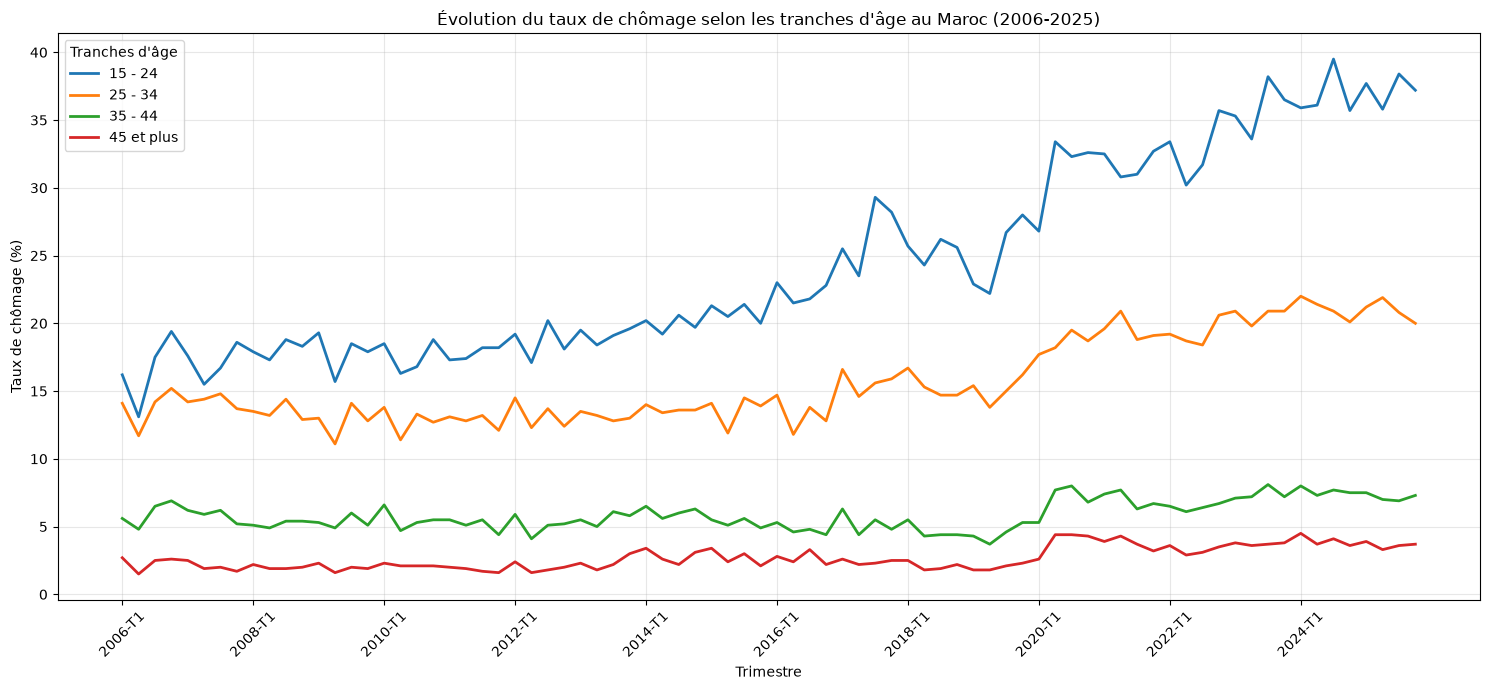

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 7))

for age in df_age_national["Tranches d'âge"].unique():

    data = df_age_national[
        df_age_national["Tranches d'âge"] == age
    ].sort_values(["Année", "Numero_trimestre"])

    plt.plot(
        range(len(data)),
        data["Taux_chomage"],
        label=age,
        linewidth=2
    )

# Afficher une étiquette tous les 2 ans environ
tick_positions = list(range(0, 80, 8))
tick_labels = (
    df_age_national[
        df_age_national["Tranches d'âge"] == "15 - 24"
    ]
    .sort_values(["Année", "Numero_trimestre"])["Periode"]
    .iloc[::8]
)

plt.xticks(tick_positions, tick_labels, rotation=45)

plt.title(
    "Évolution du taux de chômage selon les tranches d'âge au Maroc (2006-2025)"
)
plt.xlabel("Trimestre")
plt.ylabel("Taux de chômage (%)")

plt.legend(title="Tranches d'âge")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "reports/figures/unemployment_by_age_2006_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Calculer le taux moyen annuel par tranche d'âge
df_age_yearly = (
    df_age_national
    .groupby(["Tranches d'âge", "Année"])["Taux_chomage"]
    .mean()
    .reset_index()
)

# Comparer 2006 et 2025
comparison = df_age_yearly[
    df_age_yearly["Année"].isin([2006, 2025])
].pivot(
    index="Tranches d'âge",
    columns="Année",
    values="Taux_chomage"
)

comparison["Evolution_pp"] = (
    comparison[2025] - comparison[2006]
)

print("Comparaison des taux moyens annuels (en %) :")
display(comparison.round(2))

Comparaison des taux moyens annuels (en %) :


Année,2006,2025,Evolution_pp
Tranches d'âge,,,
15 - 24,16.55,37.28,20.72
25 - 34,13.80,20.98,7.18
35 - 44,5.95,7.18,1.22
45 et plus,2.33,3.63,1.30


In [ ]:
from pathlib import Path

# Project root = parent of the notebooks folder
PROJECT_ROOT = Path.cwd().parent

# Create the figures folder
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Figures folder:", FIGURES_DIR)
print("Folder exists:", FIGURES_DIR.exists())

Project root: c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence
Figures folder: c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\reports\figures
Folder exists: True


In [ ]:
plt.savefig(
    FIGURES_DIR / "unemployment_by_age_2006_2025.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [ ]:
# Filter the 15–24 age group
df_youth = df_age_long[
    df_age_long["Tranches d'âge"] == "15 - 24"
].copy()

# Keep only Urban and Rural observations
df_youth_urban_rural = df_youth[
    df_youth["Milieu"].isin(["Urbain", "Rural"])
].copy()

# Verify the result
print("Dataset shape:", df_youth_urban_rural.shape)

print("\nResidence categories:")
print(df_youth_urban_rural["Milieu"].unique())

print("\nObservations per residence:")
print(df_youth_urban_rural.groupby("Milieu").size())

display(df_youth_urban_rural.head())

Dataset shape: (160, 7)

Residence categories:
<ArrowStringArray>
['Rural', 'Urbain']
Length: 2, dtype: str

Observations per residence:
Milieu
Rural     80
Urbain    80
dtype: int64


,Tranches d'âge,Milieu,Trimestre,Taux_chomage,Année,Numero_trimestre,Periode
80,15 - 24,Rural,T1-2006,6.4,2006,1,2006-T1
81,15 - 24,Rural,T2-2006,4.3,2006,2,2006-T2
82,15 - 24,Rural,T3-2006,6.7,2006,3,2006-T3
83,15 - 24,Rural,T4-2006,7.9,2006,4,2006-T4
84,15 - 24,Rural,T1-2007,7.6,2007,1,2007-T1


In [ ]:
latest_period = df_youth_urban_rural["Année"].max()

latest_data = df_youth_urban_rural[
    df_youth_urban_rural["Année"] == latest_period
].sort_values(["Numero_trimestre"])

latest_quarter = latest_data["Numero_trimestre"].max()

latest_comparison = latest_data[
    latest_data["Numero_trimestre"] == latest_quarter
][["Milieu", "Taux_chomage"]].set_index("Milieu")

print(f"Comparison for {latest_period}-T{latest_quarter}:")
display(latest_comparison)

urban_rate = latest_comparison.loc["Urbain", "Taux_chomage"]
rural_rate = latest_comparison.loc["Rural", "Taux_chomage"]

print(f"Urban unemployment: {urban_rate}%")
print(f"Rural unemployment: {rural_rate}%")
print(f"Urban-rural gap: {urban_rate - rural_rate:.1f} percentage points")

Comparison for 2025-T4:


,Taux_chomage
Milieu,
Rural,20.4
Urbain,50.1


Urban unemployment: 50.1%
Rural unemployment: 20.4%
Urban-rural gap: 29.7 percentage points


In [ ]:
youth_yearly = (
    df_youth_urban_rural
    .groupby(["Milieu", "Année"])["Taux_chomage"]
    .mean()
    .reset_index()
)

comparison_urban_rural = youth_yearly[
    youth_yearly["Année"].isin([2006, 2025])
].pivot(
    index="Milieu",
    columns="Année",
    values="Taux_chomage"
)

comparison_urban_rural["Evolution_pp"] = (
    comparison_urban_rural[2025] -
    comparison_urban_rural[2006]
)

print("Youth unemployment: Urban vs Rural")
display(comparison_urban_rural.round(2))

Youth unemployment: Urban vs Rural


Année,2006,2025,Evolution_pp
Milieu,,,
Rural,6.32,22.88,16.55
Urbain,31.50,48.02,16.52


In [ ]:
from pathlib import Path

# Identifier automatiquement la racine du projet
current_dir = Path.cwd()

if (current_dir / "data").exists() and (current_dir / "notebooks").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "data").exists():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError("Impossible de trouver la racine du projet.")

# Définir le dossier des graphiques
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

# Créer le dossier s'il n'existe pas
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Figures folder:", FIGURES_DIR)
print("Folder exists:", FIGURES_DIR.exists())

Project root: c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence
Figures folder: c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\reports\figures
Folder exists: True


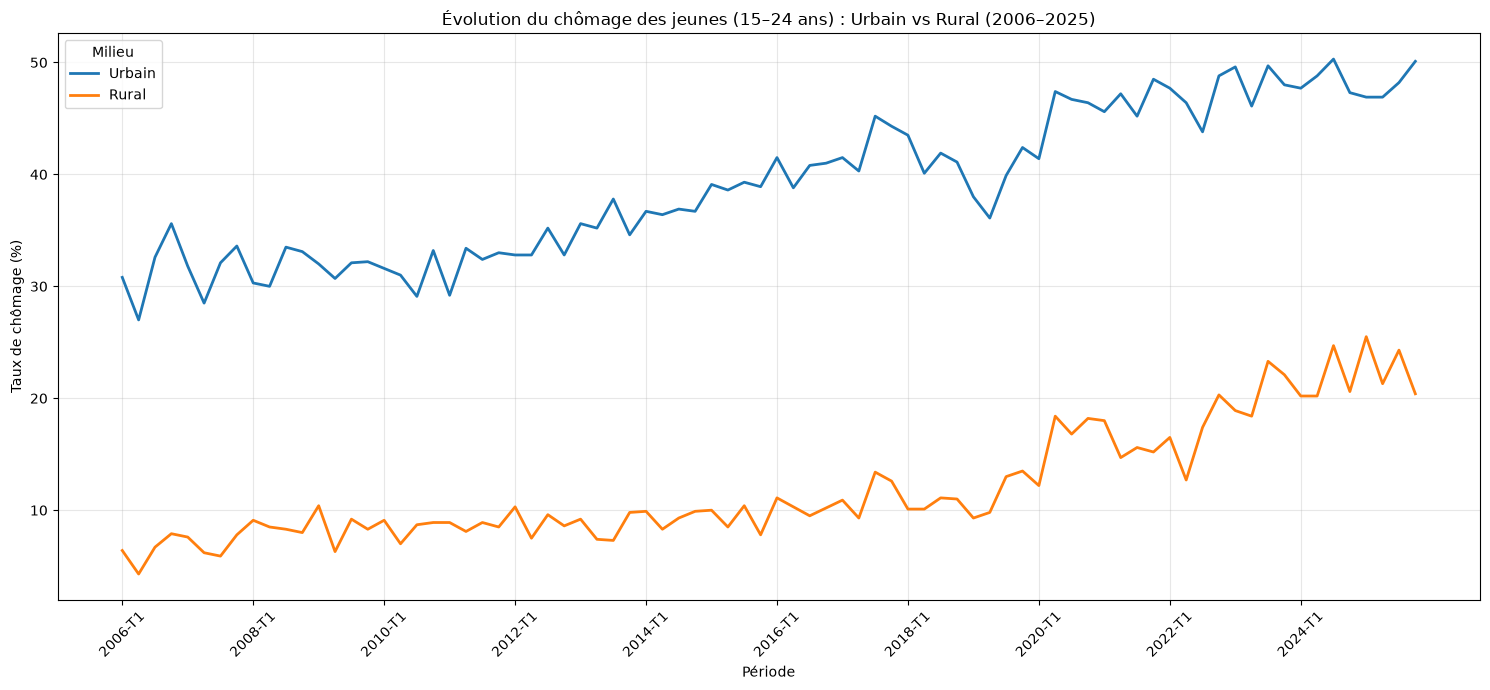

In [ ]:
import matplotlib.pyplot as plt

# Organiser les données pour comparer les deux milieux
df_youth_pivot = df_youth_urban_rural.pivot(
    index=["Année", "Numero_trimestre"],
    columns="Milieu",
    values="Taux_chomage"
).reset_index()

df_youth_pivot = df_youth_pivot.sort_values(
    ["Année", "Numero_trimestre"]
).reset_index(drop=True)

# Créer le graphique
plt.figure(figsize=(15, 7))

plt.plot(
    range(len(df_youth_pivot)),
    df_youth_pivot["Urbain"],
    label="Urbain",
    linewidth=2
)

plt.plot(
    range(len(df_youth_pivot)),
    df_youth_pivot["Rural"],
    label="Rural",
    linewidth=2
)

# Afficher une étiquette tous les deux ans
tick_positions = list(range(0, 80, 8))

tick_labels = [
    f"{year}-T1"
    for year in range(2006, 2026, 2)
]

plt.xticks(tick_positions, tick_labels, rotation=45)

plt.title(
    "Évolution du chômage des jeunes (15–24 ans) : Urbain vs Rural (2006–2025)"
)

plt.xlabel("Période")
plt.ylabel("Taux de chômage (%)")

plt.legend(title="Milieu")
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Sauvegarder le graphique
plt.savefig(
    FIGURES_DIR / "youth_unemployment_urban_vs_rural.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Calculer la différence entre les deux milieux
df_youth_pivot["Ecart_pp"] = (
    df_youth_pivot["Urbain"] - df_youth_pivot["Rural"]
)

print("Statistiques de l'écart Urbain - Rural :")

print(
    "\nÉcart moyen :",
    round(df_youth_pivot["Ecart_pp"].mean(), 2),
    "points"
)

print(
    "Écart minimum :",
    round(df_youth_pivot["Ecart_pp"].min(), 2),
    "points"
)

print(
    "Écart maximum :",
    round(df_youth_pivot["Ecart_pp"].max(), 2),
    "points"
)

print("\nLes 5 derniers trimestres :")

display(
    df_youth_pivot[
        ["Année", "Numero_trimestre", "Urbain", "Rural", "Ecart_pp"]
    ].tail(5).round(2)
)

Statistiques de l'écart Urbain - Rural :

Écart moyen : 27.07 points
Écart minimum : 20.3 points
Écart maximum : 33.7 points

Les 5 derniers trimestres :


Milieu,Année,Numero_trimestre,Urbain,Rural,Ecart_pp
75,2024,4,47.3,20.6,26.7
76,2025,1,46.9,25.5,21.4
77,2025,2,46.9,21.3,25.6
78,2025,3,48.2,24.3,23.9
79,2025,4,50.1,20.4,29.7


Milieu,Année,Urbain,Rural,Ecart_pp
0,2006,31.50,6.32,25.18
1,2007,31.50,6.88,24.62
2,2008,31.72,8.48,23.25
3,2009,31.75,8.55,23.20
4,2010,31.22,8.43,22.80
5,2011,32.00,8.60,23.40
6,2012,33.40,9.00,24.40
7,2013,35.80,8.43,27.37
8,2014,36.67,9.35,27.32
9,2015,38.98,9.18,29.80


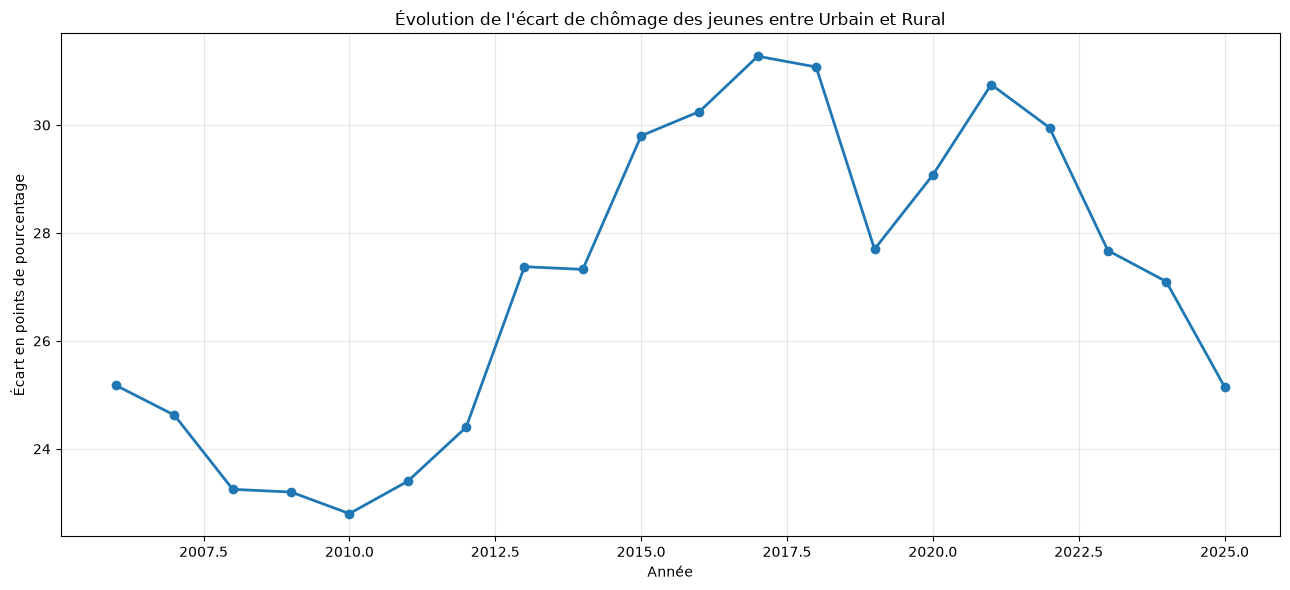

In [ ]:
# Calculer les moyennes annuelles par milieu
df_youth_annual = (
    df_youth_pivot
    .groupby("Année")[["Urbain", "Rural"]]
    .mean()
    .reset_index()
)

# Calculer l'écart annuel
df_youth_annual["Ecart_pp"] = (
    df_youth_annual["Urbain"] - df_youth_annual["Rural"]
)

display(df_youth_annual.round(2))

# Visualiser l'évolution de l'écart
plt.figure(figsize=(13, 6))

plt.plot(
    df_youth_annual["Année"],
    df_youth_annual["Ecart_pp"],
    marker="o",
    linewidth=2
)

plt.title(
    "Évolution de l'écart de chômage des jeunes entre Urbain et Rural"
)

plt.xlabel("Année")
plt.ylabel("Écart en points de pourcentage")

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "youth_unemployment_gap_urban_rural.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Analyse du chômage des jeunes selon le milieu de résidence (2006–2025)

L'analyse révèle un écart important entre les milieux urbain et rural.

- Le taux de chômage des jeunes de 15 à 24 ans est systématiquement plus élevé en milieu urbain.
- L'écart moyen trimestriel est de 27,07 points de pourcentage.
- L'écart maximal atteint 33,7 points.
- En 2025, les moyennes annuelles sont de 48,02 % en milieu urbain et 22,88 % en milieu rural.

Malgré une légère diminution de l'écart annuel entre 2006 et 2025, le chômage des jeunes reste élevé dans les deux milieux.

Ces résultats sont descriptifs et ne permettent pas, à eux seuls, d'établir une relation causale entre le milieu de résidence et le chômage.